In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")


In [2]:
import os, sys, logging

sys.path.append("../")

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
from rich.console import Console
from rich.theme import Theme
from src.utils import env_utils, logging_utils

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)


# Well-Known Task Completions — Inspection

Inspect outputs of `scripts/generate_well_known_task_completions.py`.

Each result file is a JSON dict with keys:
- `function_name` — task identifier
- `prompt` — full chat-template prompt sent to the model
- `generation` — raw LM completion


In [3]:
import json
from pathlib import Path
from src.utils.env_utils import DEFAULT_RESULTS_DIR, DEFAULT_DATA_DIR

MODEL_SHORT = "Qwen2.5-Coder-32B-Instruct"   # change to inspect a different model

RESULTS_DIR = Path(DEFAULT_RESULTS_DIR) / "well-known-task-generations" / MODEL_SHORT
TASKS_DIR   = Path(DEFAULT_DATA_DIR) / "well-known-tasks"

print(f"Results dir : {RESULTS_DIR}")
print(f"Exists      : {RESULTS_DIR.exists()}")


Results dir : /disk/u/arnab/Codes/Projects/goals/results/well-known-task-generations/Qwen2.5-Coder-32B-Instruct
Exists      : True


In [4]:
results: dict[str, dict] = {}

if RESULTS_DIR.exists():
    for path in sorted(RESULTS_DIR.glob("*.json")):
        with open(path) as f:
            results[path.stem] = json.load(f)

print(f"Loaded {len(results)} generated results")


Loaded 3 generated results


In [5]:
from rich.table import Table

# All available task names
all_tasks = sorted(p.stem for p in TASKS_DIR.glob("*.json"))

generated   = sorted(results.keys())
missing     = [t for t in all_tasks if t not in results]

table = Table(title=f"Coverage — {MODEL_SHORT}", show_lines=False, highlight=False)
table.add_column("Stat", style="bold")
table.add_column("Count", justify="right")
table.add_row("Total tasks available", str(len(all_tasks)))
table.add_row("Generated",            f"[green]{len(generated)}[/green]")
table.add_row("Missing",              f"[red]{len(missing)}[/red]")
rich_print(table)

if missing:
    rich_print(f"\n[red]Missing tasks:[/red] {', '.join(missing)}")


           Coverage —            
   Qwen2.5-Coder-32B-Instruct    
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Stat                  ┃ Count ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ Total tasks available │   134 │
│ Generated             │     3 │
│ Missing               │   131 │
└───────────────────────┴───────┘

Missing tasks: add_binary, add_two_numbers_linked_list, add_without_plus, atoi, basic_calculator, bellman_ford, 
binary_search, binary_search_leftmost, bipartite_check, bubble_sort, burst_balloons, caesar_cipher, 
climbing_stairs, coin_change, container_with_most_water, copy_list_with_random_pointer, count_and_say, count_bits, 
count_paths, count_trailing_zeros_factorial, count_vowels, counting_sort, daily_temperatures, decode_string, 
decode_ways, detect_cycle_directed, detect_cycle_linked_list, diameter_of_tree, digital_root, dutch_national_flag, 
edit_distance, evaluate_rpn, factorial, fibonacci, find_all_anagrams, flatten_nested_list, 
flatten_tree_to_linked_list, floyd_warshall, gcd, generate_parentheses, group_anagrams, hamming_distance, 
heap_sort, house_robber, inorder_traversal, insert_interval, insertion_sort, int_to_roman, is_anagram, 
is_armstrong_number, is_balanced, is_bst, is_palindrome, is_palindrome_linked_list, is_perfect_square, 
is_power_of_two, is_prime, is_subsequence, itoa, jump_game, kmp_search, knapsack_01, kruskal_mst, 
kth_largest_element, kth_smallest_bst, largest_rectangle_histogram, lcm, level_order_traversal, 
longest_common_prefix, longest_common_subsequence, longest_increasing_subsequence, longest_palindromic_substring, 
longest_substring_no_repeat, lowest_common_ancestor, matrix_chain_order, matrix_multiply, matrix_transpose, 
max_depth, max_path_sum, maximal_square, maximum_product_subarray, maximum_subarray, merge_intervals, 
merge_k_sorted_lists, merge_sort, merge_sorted_lists, min_jumps, minimum_window_substring, missing_number, mod_exp,
move_zeros, multiply_strings, n_queens, next_permutation, nth_prime, num_connected_components, number_of_islands, 
palindrome_min_cuts, path_sum, permutations, product_except_self, quick_sort, radix_sort, 
regular_expression_matching, remove_nth_from_end, reorder_list, reverse_bits, reverse_linked_list, reverse_words, 
right_side_view, rod_cutting, roman_to_int, rotate_matrix, run_length_encode, selection_sort, 
sieve_of_eratosthenes, single_number, sliding_window_max, spiral_order, sqrt_floor, strongly_connected_components, 
subsets, three_sum, top_k_frequent_elements, topological_sort, trapping_rain_water, two_sum, valid_parentheses, 
word_break, word_ladder, zigzag_level_order

2026-04-08 15:37:22 matplotlib DEBUG    matplotlib data path: /disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data
2026-04-08 15:37:22 matplotlib DEBUG    CONFIGDIR=/disk/u/arnab/.config/matplotlib
2026-04-08 15:37:22 matplotlib DEBUG    interactive is False
2026-04-08 15:37:22 matplotlib DEBUG    platform is linux
2026-04-08 15:37:22 matplotlib DEBUG    CACHEDIR=/disk/u/arnab/.cache/matplotlib
2026-04-08 15:37:22 matplotlib.font_manager DEBUG    Using fontManager instance from /disk/u/arnab/.cache/matplotlib/fontlist-v390.json
2026-04-08 15:37:22 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-08 15:37:22 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-08 15:37:22 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-04-08 15:37:22 matplotlib.font_mana

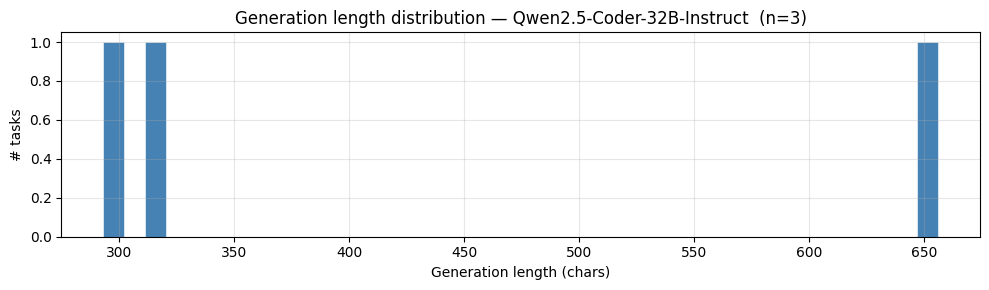

  min=293  median=315  max=656  mean=421


In [6]:
import numpy as np
import matplotlib.pyplot as plt

gen_lengths = [len(r["generation"]) for r in results.values()]

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(gen_lengths, bins=40, color="steelblue", edgecolor="white", linewidth=0.4)
ax.set_xlabel("Generation length (chars)")
ax.set_ylabel("# tasks")
ax.set_title(f"Generation length distribution — {MODEL_SHORT}  (n={len(gen_lengths)})")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"  min={min(gen_lengths)}  median={int(np.median(gen_lengths))}  "
      f"max={max(gen_lengths)}  mean={np.mean(gen_lengths):.0f}")


In [12]:
# ── Inspect a single generation ──────────────────────────────────────────────
INSPECT_TASK = "dijkstra"   # change to any task name

if INSPECT_TASK not in results:
    rich_print(f"[red]{INSPECT_TASK!r} not found in results[/red]")
else:
    r = results[INSPECT_TASK]
    rich_print(f"[bold cyan]Task:[/bold cyan] {r['function_name']}")
    rich_print(f"[white]{r['prompt']}[/white][bright_yellow]{r['generation']}[/bright_yellow]")


Task: dijkstra

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement Dijkstra's shortest path algorithm in Python. Write your code without any comments or explanations, just 
the implementation.<|im_end|>
<|im_start|>assistant
<code>
def dijkstra(graph, start):
    """Dijkstra's Algorithm implementation"""
    import heapq
    queue = []
    heapq.heappush(queue, (0, start))
    distances = {vertex: float('infinity') for vertex in graph}
    distances = 0

    while queue:
        current_distance, current_vertex = heapq.heappop(queue)

        if current_distance > distances:
            continue

        for neighbor, weight in graph.items():
            distance = current_distance + weight

            if distance < distances:
                distances = distance
                heapq.heappush(queue, (distance, neighbor))

    return distances
</code>

In [8]:
# ── Summary table: function name + first line of generation ──────────────────
from rich.table import Table

table = Table(title=f"All generations — {MODEL_SHORT}", show_lines=True, highlight=False)
table.add_column("Task", style="cyan", no_wrap=True)
table.add_column("Gen length", justify="right")
table.add_column("First line of generation", no_wrap=False, max_width=80)

for name, r in sorted(results.items()):
    first_line = r["generation"].strip().splitlines()[0] if r["generation"].strip() else "(empty)"
    table.add_row(name, str(len(r["generation"])), first_line)

rich_print(table)


                  All generations — Qwen2.5-Coder-32B-Instruct                   
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Task     ┃ Gen length ┃ First line of generation                              ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ bfs      │        315 │ Perform BFS on a graph starting from a given node.""" │
├──────────┼────────────┼───────────────────────────────────────────────────────┤
│ dfs      │        293 │ Depth First Search algorithm."""                      │
├──────────┼────────────┼───────────────────────────────────────────────────────┤
│ dijkstra │        656 │ Dijkstra's Algorithm implementation"""                │
└──────────┴────────────┴───────────────────────────────────────────────────────┘

In [13]:
print(r['generation'])

Dijkstra's Algorithm implementation"""
    import heapq
    queue = []
    heapq.heappush(queue, (0, start))
    distances = {vertex: float('infinity') for vertex in graph}
    distances[start] = 0

    while queue:
        current_distance, current_vertex = heapq.heappop(queue)

        if current_distance > distances[current_vertex]:
            continue

        for neighbor, weight in graph[current_vertex].items():
            distance = current_distance + weight

            if distance < distances[neighbor]:
                distances[neighbor] = distance
                heapq.heappush(queue, (distance, neighbor))

    return distances
</code>
